In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from sklearn.model_selection import train_test_split

In [9]:
# Load dataset
data = pd.read_csv("data.csv")

# Separate features and target
X = data.drop(columns=['id', 'diagnosis']).to_numpy(dtype=np.float64)
y = data['diagnosis'].astype(str).to_numpy()

# Check data types
print("X type:", type(X))
print("y type:", type(y))

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=2
)

# Display results
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

X type: <class 'numpy.ndarray'>
y type: <class 'numpy.ndarray'>
Training features: (455, 31)
Testing features: (114, 31)
Training labels: (455,)
Testing labels: (114,)


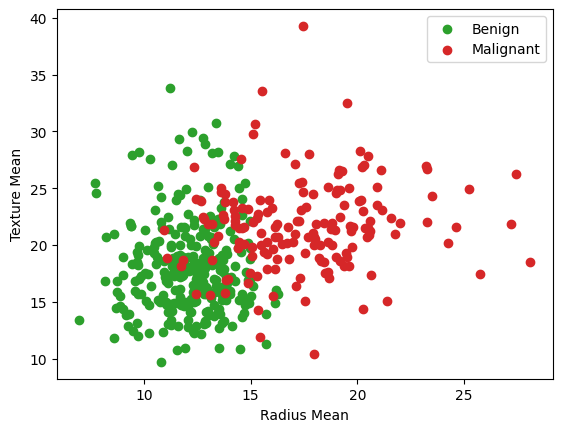

In [10]:
plt.scatter(X_train[y_train == 'B', 0], X_train[y_train == 'B', 1], color='tab:green', label='Benign')
plt.scatter(X_train[y_train == 'M', 0], X_train[y_train == 'M', 1], color='tab:red', label='Malignant')
plt.xlabel('Radius Mean')
plt.ylabel('Texture Mean')
plt.legend()
plt.show()

In [11]:
def euclidean_distance(a, b):
    return np.sqrt(np.sum((b - a) ** 2))

### --------------------------------

# KNN

In [12]:
class KNN:
    def __init__(self, k):
        self.k = k

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y

    def predict(self, new_points):
        predictions = [self.predict_class(new_point) for new_point in new_points]
        return np.array(predictions)
    
    def predict_class(self, new_point):
        distances = [euclidean_distance(point, new_point) for point in self.X_train]

        k_nearest_indices = np.argsort(distances)[:self.k]
        k_nearest_labels = [self.y_train[i] for i in k_nearest_indices]

        most_common = Counter(k_nearest_labels).most_common(1)[0][0]

        return most_common

In [13]:
knn = KNN(7)
knn.fit(X_train, y_train)
predictions = knn.predict(X_test)
accuracy = np.mean(predictions == y_test) * 100
print(f"Accuracy: {accuracy:.2f}%")

Accuracy: 60.53%


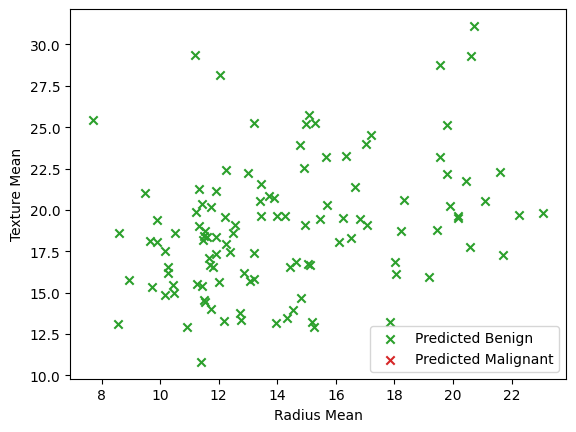

In [14]:
plt.scatter(X_test[predictions == 'B', 0], X_test[predictions == 'B', 1], color='tab:green', label='Predicted Benign', marker='x')
plt.scatter(X_test[predictions == 'M', 0], X_test[predictions == 'M', 1], color='tab:red', label='Predicted Malignant', marker='x')
plt.xlabel('Radius Mean')
plt.ylabel('Texture Mean')
plt.legend()
plt.show()